Training and validation were performed with the SwissProt Training/Validation dataset used to train the DeepLoc 2.0 server. Testing was performed using the DeepLoc 2.0 Human Protein Atlas (HPA) test set. The data is available at: https://services.healthtech.dtu.dk/services/DeepLoc-2.0/4-Data.php

**References**

Thumuluri, V., Almagro Armenteros, J. J., Johansen, A. R., Nielsen, H. & Winther, O. (2022). *DeepLoc 2.0: multi-label subcellular localization prediction using protein language models.* Nucleic Acids Research, 50(W1), W228–W234. https://doi.org/10.1093/nar/gkac278

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

def sigmoid(z):
    g = 1/(1+np.exp(-z))
    return g

In [2]:
def compute_cost_logistic(x,y,w,b, lmbda):
    m = x.shape[0]
    n = len(w)
    cost = 0.
    for i in range(m):
        z_i = np.dot(x[i], w) + b
        f_wb_i = sigmoid(z_i)
        cost += y[i]*np.log(f_wb_i) + (1 - y[i])*np.log(1  - f_wb_i)
    cost = cost / -m

    reg_cost = 0 #for regularisation term
    for j in range(n):
        reg_cost += (w[j] ** 2)
    reg_cost = (lmbda / (2*m)) * reg_cost
    total_cost = cost + reg_cost
    return total_cost

In [3]:
def compute_gradient_logistic(x,y,w,b, lmbda):
    m,n = x.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.

    for i in range(m):
        f_wb_i = sigmoid(np.dot(x[i],w) + b)
        err_i = f_wb_i - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err_i*x[i,j]
        dj_db = dj_db + err_i
    dj_dw = dj_dw/m
    dj_db = dj_db/m

    for j in range(n):
        dj_dw[j] = dj_dw[j] + (lmbda/m)*w[j]
    
    return dj_dw, dj_db

In [4]:
def gradient_descent(x, y, w, b, alpha, num_iters, lmbda):
    J_history = [] # for plotting learning curve
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_logistic(x, y, w, b, lmbda)
        w = w - alpha*dj_dw
        b = b - alpha*dj_db
        J_history.append(compute_cost_logistic(x,y,w,b,lmbda))
    return w,b, J_history

In [5]:
df = pd.read_csv("Protein_localisation_data/Training_CV_set.csv")
df.head()

,Unnamed: 0,Kingdom,Partition,Nucleus,Sequence,input_vectors
0,0,Metazoa,4,1.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,[0.11437908 0.09150327 0.03594771 0.03267974 0...
1,1,Metazoa,4,1.0,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,[0.11437908 0.09150327 0.03267974 0.03267974 0...
2,2,Metazoa,3,0.0,MAAAAAAAAALGVRLRDCCSRGAVLLLFFSLSPRPPAAAAWLLGLR...,[0.0893796 0.07781283 0.02944269 0.05152471 0...
3,3,Metazoa,1,0.0,MAAAAAAAAATEQQGSNGPVKKSMREKAVERRNVNKEHNSNFKAGY...,[0.059375 0.05 0.071875 0.04375 0.01875 ...
4,4,Metazoa,1,1.0,MAAAAAAAAATNGTGGSSGMEVDAAVVPSVMACGVTGSVSVALHPL...,[0.08562691 0.03669725 0.03975535 0.03975535 0...


In [6]:
test_df = pd.read_csv("Protein_localisation_data/Test_set.csv")
test_df.head()

,Unnamed: 0,Nucleus,Sequence,input_vectors
0,0,1,MAAAAGPGAALSPRPCDSDPATPGAQSPKDDNEDNSNDGTQPSKRR...,[0.05443548 0.06048387 0.03225806 0.06451613 0...
1,1,1,MAAAALRDPAQVPVAADLLTDHEEGYVTFEDVAVYFSQEEWRLLDD...,[0.0982659 0.06358382 0.01734104 0.03468208 0...
2,2,0,MAAAAQSRVVRVLSMSRSAITAIATSVCHGPPCRQLHHALMPHGKG...,[0.0795756 0.07692308 0.02917772 0.05039788 0...
3,3,0,MAAAAVGAGHGAGGPGAASSSGGAREGARVAALCLLWYALSAGGNV...,[0.09512195 0.04390244 0.04146341 0.02195122 0...
4,4,1,MAAAAVTRGTPGENSHHLKIFLPKKLLECLPRCPLLPPERLRWNTN...,[0.06748466 0.0797546 0.03680982 0.02453988 0...


In [7]:
#from the csv file, numerical array data type was lost & input_vectors column is being read as strings
print(type(df["input_vectors"].iloc[0]))
df["input_vectors"] = df["input_vectors"].apply(lambda x: np.fromstring(x.strip("[]"), sep=" "))
print(type(df["input_vectors"].iloc[0]))

#first step of 5-fold cross-validation will use homology partition 0 as the validation set
train_df = df[df["Partition"].isin([1, 2, 3, 4])]
X_train = np.stack(train_df["input_vectors"].values)
y_train = np.stack(train_df["Nucleus"].values)

cv_df = df[df["Partition"] == 0]
X_cv = np.stack(cv_df["input_vectors"].values)
y_cv = np.stack(cv_df["Nucleus"].values)

<class 'str'>
<class 'numpy.ndarray'>


In [8]:
print(type(test_df["input_vectors"].iloc[0]))
test_df["input_vectors"] = test_df["input_vectors"].apply(lambda x: np.fromstring(x.strip("[]"), sep=" "))
print(type(test_df["input_vectors"].iloc[0]))

X_test = np.stack(test_df["input_vectors"].values)
y_test = np.stack(test_df["Nucleus"].values)

<class 'str'>
<class 'numpy.ndarray'>


In [9]:
w_init = np.zeros_like(X_train[0])
b_init = 0
num_iters = 100
w, b, J_history = gradient_descent(X_train, y_train, w_init, b_init, 0.5, num_iters, 0)
print("The fitted values of w for each feature are", w)
print("The fitted value of b is", b)
print("The final cost was", J_history[99])
x_cost = np.arange(0, num_iters, 1)

The fitted values of w for each feature are [-0.09538482  0.02854244  0.00314888  0.03802543 -0.05722341  0.05571657
  0.07707174 -0.08844717  0.01642521 -0.09263948 -0.17830104  0.0476445
 -0.01766835 -0.10286144  0.04105111  0.04095776 -0.06266226 -0.04555566
 -0.05386071 -0.13366451]
The fitted value of b is -0.5799012387365452
The final cost was 0.6463498166022338


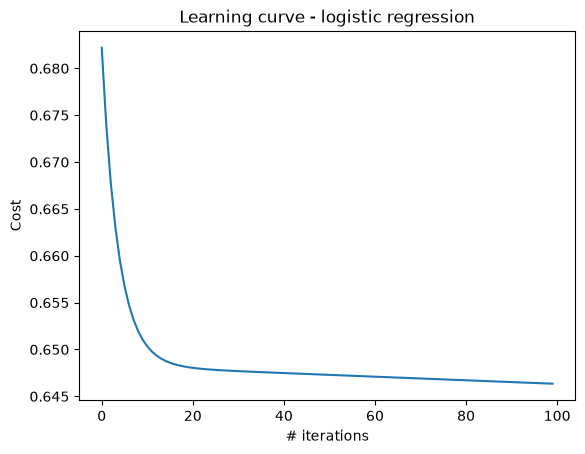

In [10]:
plt.plot(x_cost, J_history)
plt.title("Learning curve - logistic regression")
plt.xlabel("# iterations")
plt.ylabel("Cost")
plt.show()

In [21]:
def predict_probability(x, w, b):
    z = np.dot(w, x) + b
    y_hat = sigmoid(z)
    return y_hat

In [22]:
np.mean(y_train)

np.float64(0.35134288272157566)

In [23]:
classifications = []
for i in range(200):
    classifications.append(predict_probability(X_train[i], w, b))  
print(classifications)

[np.float64(0.3536465400049246), np.float64(0.35367485337539556), np.float64(0.34972284978960083), np.float64(0.3502745666713212), np.float64(0.3494433489984123), np.float64(0.3497079550293783), np.float64(0.35041318795829285), np.float64(0.34944369395381075), np.float64(0.3499706497855308), np.float64(0.3516282559936922), np.float64(0.35043476617525054), np.float64(0.35041191768321794), np.float64(0.35077751147080966), np.float64(0.35149986550859974), np.float64(0.35272778432361895), np.float64(0.35206263604290994), np.float64(0.350552660082844), np.float64(0.34957631683003704), np.float64(0.35077927705039336), np.float64(0.3518646501440026), np.float64(0.35285611877182027), np.float64(0.348287820118443), np.float64(0.34850668339358626), np.float64(0.3505245309979912), np.float64(0.35245425888248727), np.float64(0.3515115067884117), np.float64(0.35371472369657575), np.float64(0.3517736647444673), np.float64(0.34996690344636755), np.float64(0.34918069662632695), np.float64(0.3496666949

Probability predictions are extremely concentrated around the proportion of nuclear proteins in the training set, predicting almost identical probabilities for every protein due to extremely small fitted w parameters. This was resolved by incorporating Z-score normalization with scikit-learn.

In [24]:
#feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_cv_scaled = scaler.transform(X_cv)

In [25]:
w_init = np.zeros_like(X_train[0])
b_init = 0
num_iters = 100
w, b, J_history = gradient_descent(X_train_scaled, y_train, w_init, b_init, 0.5, num_iters, 0)
print("The fitted values of w for each feature are", w)
print("The fitted value of b is", b)
print("The final cost was", J_history[99])
x_cost = np.arange(0, num_iters, 1)

The fitted values of w for each feature are [-0.16755405  0.12801341  0.05491037  0.29808878 -0.15961164  0.20454401
  0.09934227 -0.0992049   0.22925299 -0.08559089 -0.29108128  0.15134125
  0.03707993 -0.20538903  0.22885736  0.16764135 -0.13732596 -0.26942251
 -0.08396703 -0.2267588 ]
The fitted value of b is -0.772431179905124
The final cost was 0.5486976072518461


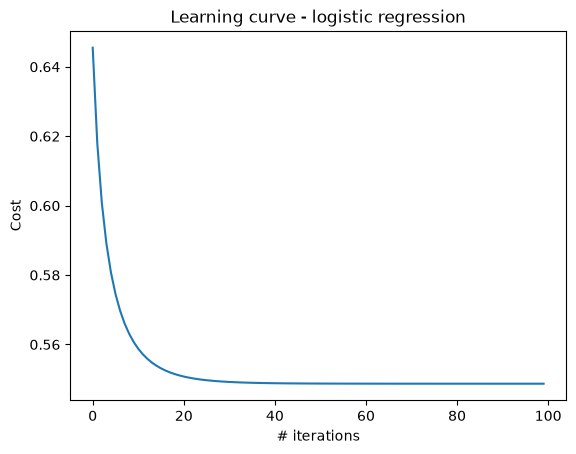

In [26]:
plt.plot(x_cost, J_history)
plt.title("Learning curve - logistic regression")
plt.xlabel("# iterations")
plt.ylabel("Cost")
plt.show()

In [28]:
classifications = []
for i in range(200):
    classifications.append(predict_probability(X_train_scaled[i], w, b))  
print(classifications)

[np.float64(0.49434230816673624), np.float64(0.4991883142538189), np.float64(0.22313645687587547), np.float64(0.276997636593239), np.float64(0.17387521907625872), np.float64(0.16423520348235673), np.float64(0.3779900675927066), np.float64(0.22562114371728112), np.float64(0.25150266604858834), np.float64(0.43138691428759857), np.float64(0.3332055861181107), np.float64(0.28816302731771176), np.float64(0.1716168884008336), np.float64(0.3193268137686485), np.float64(0.33787852803928276), np.float64(0.47118700068523217), np.float64(0.2467415747689333), np.float64(0.16499458305846842), np.float64(0.2876970688411842), np.float64(0.4023823896798908), np.float64(0.7161559543481695), np.float64(0.17590645221994555), np.float64(0.125535832160854), np.float64(0.31157384264956284), np.float64(0.43708346302695417), np.float64(0.4360806310259493), np.float64(0.5202947638614034), np.float64(0.34392303622380355), np.float64(0.31066162532483027), np.float64(0.19895935023240113), np.float64(0.24439295459

In [29]:
def predict(x, w, b):
    z = np.dot(w, x) + b
    y_hat = sigmoid(z)
    if y_hat >= 0.5:
        return 1
    else:
        return 0

In [30]:
classifications = []
for i in range(len(X_train_scaled)):
    classifications.append(predict(X_train_scaled[i], w, b))

count = 0
for i in range(len(classifications)):
    if classifications[i] != y_train[i]:
        count += 1
print("% misclassified in training set is", count/len(classifications)*100, "%")

classifications = []
for i in range(len(X_cv_scaled)):
    classifications.append(predict(X_cv_scaled[i], w, b))

count = 0
for i in range(len(X_cv)):
    if classifications[i] != y_cv[i]:
        count += 1
print("% misclassified in cv set is", count/len(y_cv)*100, "%")

% misclassified in training set is 29.252461951656223 %
% misclassified in cv set is 27.268153613952705 %


In [31]:
X_test_scaled = scaler.transform(X_test)

In [32]:
classifications = []
for i in range(len(X_test)):
    classifications.append(predict(X_test[i], w, b))

count = 0
for i in range(len(classifications)):
    if classifications[i] != y_test[i]:
        count += 1
print("% misclassified is", count / len(classifications)*100, "%")

% misclassified is 52.00931857891672 %
